In [ ]:

# MINI-PROJECT: COVID-19 CT RADIOMICS
# Practice version using artificial data only.
# These are NOT real patient records.

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    roc_auc_score
)

# 1. Create artificial radiomic features
np.random.seed(42)
n = 600

data = pd.DataFrame({
    "texture_feature": np.random.normal(0, 1, n),
    "intensity_feature": np.random.normal(0, 1, n),
    "lung_pattern_feature": np.random.normal(0, 1, n),
    "shape_feature": np.random.normal(0, 1, n),
    "density_feature": np.random.normal(0, 1, n)
})

# 2. Create artificial outcome labels for practice
# These labels are simulated, NOT actual medical outcomes.

def create_demo_label(score):
    probability = 1 / (1 + np.exp(-score))
    return (np.random.random(n) < probability).astype(int)

data["ICU_admission"] = create_demo_label(
    0.8 * data["texture_feature"]
    + 0.7 * data["density_feature"]
)

data["Mechanical_ventilation"] = create_demo_label(
    0.8 * data["intensity_feature"]
    + 0.8 * data["lung_pattern_feature"]
)

data["Death"] = create_demo_label(
    0.8 * data["shape_feature"]
    + 0.8 * data["density_feature"]
)

print("Dataset shape:", data.shape)
print("\nFirst five rows:")
print(data.head())

# 3. Select input features
features = [
    "texture_feature",
    "intensity_feature",
    "lung_pattern_feature",
    "shape_feature",
    "density_feature"
]

X = data[features]

# 4. Train and evaluate one model per outcome
outcomes = [
    "ICU_admission",
    "Mechanical_ventilation",
    "Death"
]

for outcome in outcomes:
    print("\n" + "=" * 45)
    print("OUTCOME:", outcome)

    y = data[outcome]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )

    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    )

    # 5. Train the model
    model.fit(X_train, y_train)

    # 6. Make predictions
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    # 7. Evaluate performance
    print("Training rows:", len(X_train))
    print("Testing rows:", len(X_test))
    print("Accuracy:", round(
        accuracy_score(y_test, predictions), 3
    ))
    print("ROC-AUC:", round(
        roc_auc_score(y_test, probabilities), 3
    ))

    print("\nClassification report:")
    print(classification_report(
        y_test, predictions,
        zero_division=0
    ))

print("\nPractice experiment completed!")
print("Remember: artificial data, not clinical evidence.")

Dataset shape: (600, 8)

First five rows:
   texture_feature  intensity_feature  lung_pattern_feature  shape_feature  \
0         0.496714           0.756989              0.125225       1.901191   
1        -0.138264          -0.922165             -0.429406      -0.060661   
2         0.647689           0.869606              0.122298      -0.708407   
3         1.523030           1.355638              0.543298      -1.513714   
4        -0.234153           0.413435              0.048860      -1.803140   

   density_feature  ICU_admission  Mechanical_ventilation  Death  
0        -0.721738              0                       1      0  
1         0.176821              0                       0      1  
2        -0.546680              1                       0      0  
3        -0.271655              0                       1      1  
4         1.673452              1                       0      0  

OUTCOME: ICU_admission
Training rows: 480
Testing rows: 120
Accuracy: 0.675
ROC-AUC: 0

In [ ]:
import pandas as pd

df = pd.read_excel("/content/Dataset-description_Sept21.xlsx")

df.head()

,Patient ID,Sex,Baseline scanner,Follow-up Scanner,Baseline clinical score,Follow-up clinical score,Intensive care unit
0,1,M,Toshiba,Siemens,3,3,NO
1,2,M,Toshiba,-,2,-,NO
2,3,F,Toshiba,-,5,-,NO
3,4,F,Toshiba,-,4,-,YES
4,5,F,Toshiba,-,2,-,NO


In [ ]:
df.shape

(81, 7)

In [ ]:
df.columns

Index(['Patient ID', 'Sex', 'Baseline scanner', 'Follow-up Scanner',
       'Baseline clinical score', 'Follow-up clinical score',
       'Intensive care unit'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 81 entries, 0 to 80
Data columns (total 7 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Patient ID                81 non-null     int64 
 1   Sex                       81 non-null     object
 2   Baseline scanner          81 non-null     object
 3   Follow-up Scanner         81 non-null     object
 4   Baseline clinical score   81 non-null     int64 
 5   Follow-up clinical score  81 non-null     object
 6   Intensive care unit       81 non-null     object
dtypes: int64(2), object(5)
memory usage: 4.6+ KB


In [ ]:
df["Intensive care unit"].value_counts()

,count
Intensive care unit,
NO,48
YES,33


In [ ]:
df["ICU"] = df["Intensive care unit"].map({"NO": 0, "YES": 1})

df[["Intensive care unit", "ICU"]].head()

,Intensive care unit,ICU
0,NO,0
1,NO,0
2,NO,0
3,YES,1
4,NO,0


In [ ]:
df.head()

,Patient ID,Sex,Baseline scanner,Follow-up Scanner,Baseline clinical score,Follow-up clinical score,Intensive care unit,ICU
0,1,M,Toshiba,Siemens,3,3,NO,0
1,2,M,Toshiba,-,2,-,NO,0
2,3,F,Toshiba,-,5,-,NO,0
3,4,F,Toshiba,-,4,-,YES,1
4,5,F,Toshiba,-,2,-,NO,0


In [ ]:
df["Baseline clinical score"].value_counts().sort_index()

,count
Baseline clinical score,
0,6
1,4
2,15
3,21
4,19
5,16


In [ ]:
pd.crosstab(df["Baseline clinical score"], df["ICU"])

ICU,0,1
Baseline clinical score,,
0,6,0
1,4,0
2,15,0
3,14,7
4,5,14
5,4,12


In [ ]:
pd.crosstab(df["Sex"], df["ICU"])

ICU,0,1
Sex,,
F,25,14
M,23,19


In [ ]:
pd.crosstab(df["Baseline scanner"], df["ICU"])

ICU,0,1
Baseline scanner,,
Siemens,34,29
Toshiba,14,4


In [ ]:
pd.crosstab(df["Follow-up Scanner"], df["ICU"])

ICU,0,1
Follow-up Scanner,,
Siemens,1,0
-,36,33
Siemens,11,0


In [ ]:
df["Follow-up clinical score"].value_counts()

,count
Follow-up clinical score,
-,69
0,5
2,3
1,2
3,1
5,1


In [ ]:
df[["Baseline clinical score", "Sex", "Baseline scanner", "ICU"]].head(10)

,Baseline clinical score,Sex,Baseline scanner,ICU
0,3,M,Toshiba,0
1,2,M,Toshiba,0
2,5,F,Toshiba,0
3,4,F,Toshiba,1
4,2,F,Toshiba,0
5,2,F,Toshiba,0
6,3,F,Toshiba,0
7,1,M,Toshiba,0
8,2,F,Toshiba,0
9,5,F,Toshiba,1


In [ ]:
X = pd.get_dummies(
    df[["Baseline clinical score", "Sex", "Baseline scanner"]],
    drop_first=True
)

y = df["ICU"]

X.head()

,Baseline clinical score,Sex_M,Baseline scanner_Toshiba
0,3,True,True
1,2,True,True
2,5,False,True
3,4,False,True
4,2,False,True


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 64
Testing samples: 17


In [ ]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(random_state=42)

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [ ]:
y_pred = model.predict(X_test)

print(y_pred)

[1 1 0 0 0 0 0 0 1 0 1 1 0 0 0 0 0]


In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.8823529411764706


In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[10  0]
 [ 2  5]]


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.83      1.00      0.91        10
           1       1.00      0.71      0.83         7

    accuracy                           0.88        17
   macro avg       0.92      0.86      0.87        17
weighted avg       0.90      0.88      0.88        17



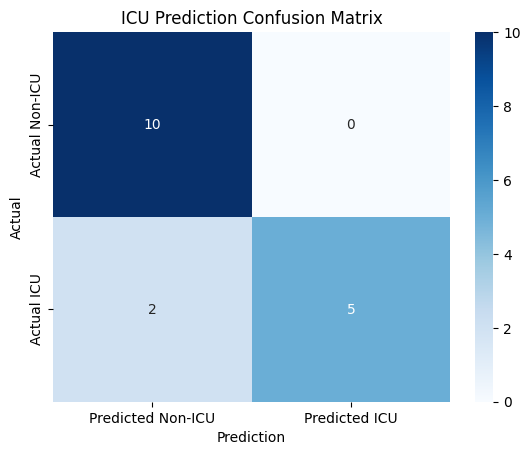

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted Non-ICU", "Predicted ICU"],
    yticklabels=["Actual Non-ICU", "Actual ICU"]
)

plt.xlabel("Prediction")
plt.ylabel("Actual")
plt.title("ICU Prediction Confusion Matrix")
plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
for feature, coefficient in zip(X.columns, model.coef_[0]):
    print(feature, ":", coefficient)

Baseline clinical score : 1.2306430627478158
Sex_M : 0.39708646026977684
Baseline scanner_Toshiba : -1.0181771543338332


AUC: 0.9928571428571428


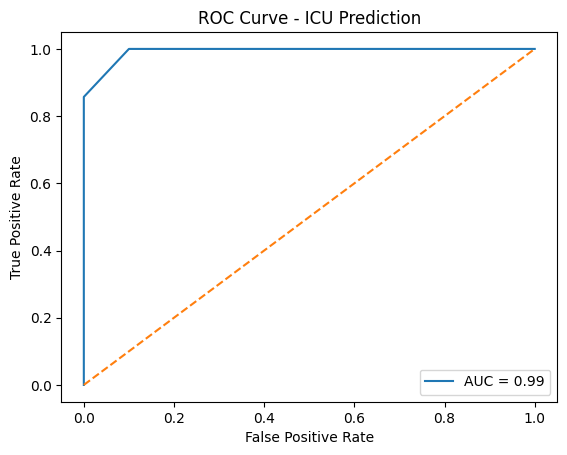

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

y_prob = model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

print("AUC:", auc)

plt.plot(fpr, tpr, label=f"AUC = {auc:.2f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - ICU Prediction")
plt.legend()
plt.savefig("roc_curve.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
results = {
    "Metric": ["Accuracy", "AUC"],
    "Value": [accuracy, auc]
}

import pandas as pd
pd.DataFrame(results)

,Metric,Value
0,Accuracy,0.882353
1,AUC,0.992857


In [ ]:
print("Number of patients:", len(df))
print("\nICU distribution:")
print(df["ICU"].value_counts())

print("\nFeatures used:")
print(list(X.columns))

Number of patients: 81

ICU distribution:
ICU
0    48
1    33
Name: count, dtype: int64

Features used:
['Baseline clinical score', 'Sex_M', 'Baseline scanner_Toshiba']
